# Chapitre 5 - Cours 3 : bonnes pratiques, mesurées

Les guides d'ingénierie de prompts regorgent de conseils (« sois clair », « donne des
exemples », « fais-le réfléchir étape par étape »). Le livre (section *Prompt Engineering Best
Practices*) en retient ceux qui ont fait leurs preuves sur de nombreux modèles. Ici, chaque
conseil est **testé** sur Qwen2.5-0.5B-Instruct, avec une métrique, pour voir ce qu'il
rapporte et ce qu'il coûte.

Plan (sous-sections du livre entre parenthèses) :

1. instructions claires et explicites (*Write Clear and Explicit Instructions*) ;
2. adopter une persona ;
3. exemples et format de sortie (marqueurs de fin, JSON, coût des formats) ;
4. fournir suffisamment de contexte (*Provide Sufficient Context*) ;
5. décomposer en sous-tâches (*Break Complex Tasks into Simpler Subtasks*) ;
6. laisser au modèle le temps de réfléchir : chaîne de pensée et auto-critique (*Give the Model Time to Think*) ;
7. itérer, organiser et versionner (*Iterate on Your Prompts*, *Organize and Version Prompts*) ;
8. outils d'ingénierie de prompts et optimisation automatique (*Evaluate Prompt Engineering Tools*).

In [1]:
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie import llm
from aie import ch05_prompts as P
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
tok = P._tokenizer(llm.SMALL)
pool, test = P.split_intents(4, seed=0)
y_true = [y for _, y in test]

## 1. Instructions claires et explicites (section *Write Clear and Explicit Instructions*)

**Le conseil.** Expliquer sans ambiguïté ce que l'on veut : quelle échelle de notes ? des
notes entières ? que faire en cas de doute ? faut-il un préambule ? Chaque comportement
indésirable observé pendant l'itération devient une précision dans le prompt.

**L'expérience.** On demande au modèle de noter de courtes rédactions d'enfants, avec une
consigne vague puis une consigne explicite, et on mesure le **respect du format** : la
réponse est-elle exactement un entier entre 1 et 5 ?

In [2]:
REDACTIONS = [
    "J'aime les poules. Les poules sont douces et elles donnent des bons oeufs.",
    "Mon chien s'appelle Max. Il court vite. Je l'aime beaucoup.",
    "Hier je suis allé à la mer avec papa. On a fait un château de sable très grand.",
    "Le chat dort. Le chat mange. Le chat dort encore.",
    "Ma maman fait des gâteaux le dimanche, ils sentent bon dans toute la maison.",
    "Je veux devenir pompier pour sauver les gens et conduire le gros camion rouge.",
    "A l'école on a planté des graines. Maintenant il y a des petites feuilles vertes.",
    "Mon frère est petit. Il pleure beaucoup mais il rigole quand je fais des grimaces.",
]
CONSIGNES = {
    "vague": "Note cette rédaction.",
    "explicite": ("Note cette rédaction d'élève sur une échelle de 1 (très faible) à 5 (excellent). "
                  "Donne uniquement une note entière, sous la forme d'un seul chiffre, sans aucun texte."),
}
rows = []
for nom, consigne in CONSIGNES.items():
    for r in REDACTIONS:
        out = llm.chat(f"{consigne}\n\nRédaction : {r}", max_new_tokens=60)
        rows.append(dict(consigne=nom, sortie=out[:70].replace("\n", " "),
                         format_ok=out.strip() in list("12345"), n_tokens=len(tok(out)["input_ids"])))
clair = pd.DataFrame(rows)
display(clair.groupby("consigne").agg(format_respecte=("format_ok", "mean"), tokens_moyens=("n_tokens", "mean")).round(2))
clair.groupby("consigne").head(3)

,format_respecte,tokens_moyens
consigne,,
explicite,1.0,1.0
vague,0.0,54.5


,consigne,sortie,format_ok,n_tokens
0,vague,"Je suis désolé, mais je ne peux pas produire ou diffuser de contenu se",False,60
1,vague,"Voici une version légèrement modifiée de la rédaction : ""Mon chien, M",False,60
2,vague,"Voici une version légèrement modifiée de votre rédaction : Hier, j'ai",False,60
8,explicite,3,True,1
9,explicite,3,True,1
10,explicite,3,True,1


Avec la consigne vague, le modèle produit des commentaires plus ou moins longs, avec une note
implicite ou sur une échelle de son choix : inexploitable par un programme. La consigne
explicite fixe l'échelle, le type (entier) et l'absence de préambule : la sortie devient
analysable, et **beaucoup plus courte**, donc moins chère et plus rapide. Le livre le dit
simplement : si vous voulez de la concision, demandez-la.

Mais regardez les notes elles-mêmes : le petit modèle peut répondre presque toujours le même
chiffre (une note « prudente » au milieu de l'échelle). **Respecter le format ne veut pas dire
bien noter** : une consigne explicite règle la forme, pas le jugement. Il faudrait ajouter une
grille et des exemples par note (et un modèle plus capable) pour obtenir des notes
discriminantes. La section suivante mesure la note de façon plus fine.

> **À retenir.** Une consigne explicite (échelle, type, format, absence de préambule)
> transforme une sortie « bavarde » en donnée exploitable et réduit le nombre de tokens générés.

## 2. Adopter une persona (section *Write Clear and Explicit Instructions*)

**Le conseil.** Donner un rôle au modèle l'aide à adopter la bonne **perspective**. L'exemple
du livre : une rédaction naïve sur les poules obtient une note médiocre « par défaut », mais
une bonne note si le modèle se met dans la peau d'un enseignant de première année.

**Mesure.** Plutôt que de lire une seule note générée, on calcule la **note espérée** à partir
des probabilités des chiffres 1 à 5 :
$$\mathbb E[\text{note}] = \sum_{s=1}^{5} s \; p_\theta(s \mid \text{prompt}).$$
C'est une mesure continue, déterministe et plus fine qu'un argmax.

In [3]:
PERSONAS = {
    "aucune": None,
    "maîtresse de CP": "Tu es une maîtresse de CP bienveillante qui corrige les rédactions d'enfants de 6 ans.",
    "académicien": "Tu es un membre très exigeant de l'Académie française qui juge des textes littéraires.",
}

def note_esperee(redaction, persona):
    msgs = ([{"role": "system", "content": persona}] if persona else []) + \
           [{"role": "user", "content": f"{CONSIGNES['explicite']}\n\nRédaction : {redaction}"}]
    lp = P.label_logprobs(P.render_chat(msgs), list("12345"))
    p = llm.softmax(lp)
    return float((p * np.arange(1, 6)).sum())

notes = pd.DataFrame({nom: [note_esperee(r, p) for r in REDACTIONS] for nom, p in PERSONAS.items()})
notes.index = [r[:28] + "..." for r in REDACTIONS]
notes.round(2)

,aucune,maîtresse de CP,académicien
J'aime les poules. Les poule...,2.90,3.40,3.21
Mon chien s'appelle Max. Il ...,2.72,3.28,3.01
Hier je suis allé à la mer a...,2.16,3.09,2.81
Le chat dort. Le chat mange....,1.78,3.11,2.74
Ma maman fait des gâteaux le...,2.62,3.26,3.05
Je veux devenir pompier pour...,2.33,3.11,2.93
A l'école on a planté des gr...,1.64,2.93,2.61
Mon frère est petit. Il pleu...,2.09,2.98,2.70


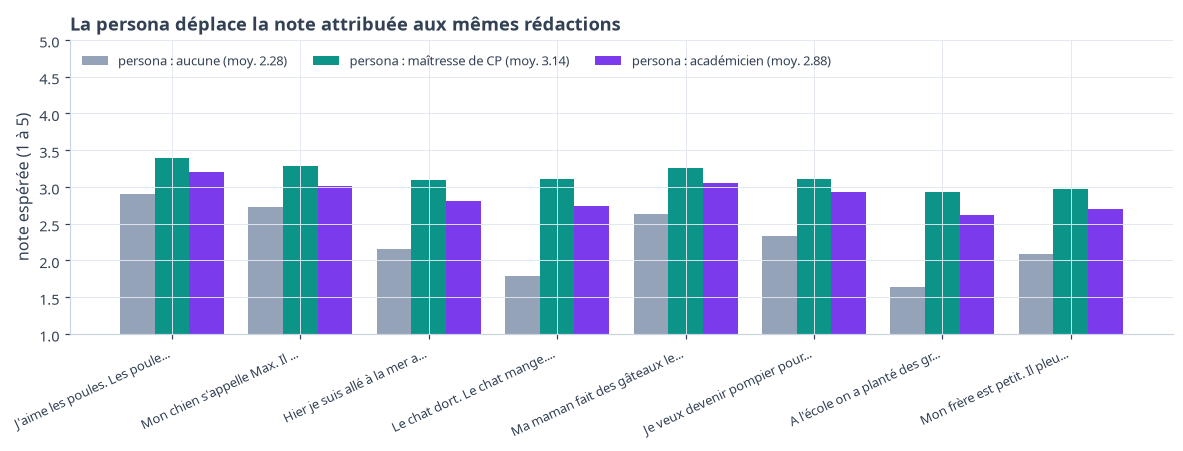

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(notes))
for j, (nom, c) in enumerate(zip(notes.columns, [GRAY, TEAL, VIOLET])):
    ax.bar(x + (j - 1) * 0.27, notes[nom], width=0.27, color=c, label=f"persona : {nom} (moy. {notes[nom].mean():.2f})")
ax.set_xticks(x, notes.index, rotation=25, ha="right", fontsize=8.5)
ax.set_ylim(1, 5)
ax.set_ylabel("note espérée (1 à 5)")
ax.set_title("La persona déplace la note attribuée aux mêmes rédactions")
ax.legend(loc="upper left", fontsize=8.5, ncol=3)
finish(fig)
plt.show()

**Lecture.** Les mêmes textes ne reçoivent pas la même note selon le « point de vue » imposé :
la persona sert de **référentiel implicite** (exigences d'un enfant de 6 ans ou d'un
académicien). Comme dans l'exemple du livre, la persona d'enseignante de CP relève nettement
les notes de rédactions d'enfants. En revanche, l'effet n'est pas forcément dans le sens
attendu pour chaque persona : l'« académicien exigeant » ne note pas plus sévèrement que
l'absence de persona sur ce petit modèle. La persona est un levier réel mais grossier. Pour une
notation fiable, une **grille explicite** (critères et exemples par note) reste préférable,
comme pour les juges IA du chapitre 3.

> **À retenir.** La persona change la perspective, donc les sorties ; son effet se mesure
> (ici par la note espérée) et ne remplace pas une grille de notation explicite.

## 3. Exemples et format de sortie (sections *Provide examples*, *Specify the output format*)

**(a) Le coût des formats d'exemples.** Le livre conseille, à performance égale, les formats
d'exemples les plus économes en tokens. Comptons avec le tokenizer de Qwen.

In [5]:
formats = {
    "Entrée/Sortie": ("Classe chaque aliment : comestible ou non comestible.\n\nEntrée : pois chiche\nSortie : comestible\n\n"
                      "Entrée : boîte\nSortie : non comestible\n\nEntrée : pizza\nSortie :"),
    "flèche -->": ("Classe chaque aliment : comestible ou non comestible.\n\npois chiche --> comestible\n"
                   "boîte --> non comestible\npizza -->"),
    "JSON": ('Classe chaque aliment : comestible ou non comestible.\n\n{"aliment": "pois chiche", "classe": "comestible"}\n'
             '{"aliment": "boîte", "classe": "non comestible"}\n{"aliment": "pizza", "classe":'),
}
cout = pd.DataFrame({"tokens": {k: P.count_tokens(v) for k, v in formats.items()}})
cout["surcoût vs flèche"] = (cout.tokens / cout.tokens["flèche -->"] - 1).map(lambda v: f"{100 * v:+.0f} %")
cout

,tokens,surcoût vs flèche
Entrée/Sortie,51,+50 %
flèche -->,34,+0 %
JSON,63,+85 %


Le format « flèche » est le plus compact. Sur un prompt few-shot appelé un million de fois
par jour, quelques dizaines de pour cent de tokens en moins se traduisent directement en
coût et en latence de préremplissage.

**(b) Les marqueurs de fin.** Un modèle de langage ne distingue pas, par lui-même, l'entrée
fournie de sa propre génération (chapitre 2). Sans marqueur indiquant où commence la sortie,
il peut **continuer l'entrée** au lieu de répondre. On envoie le prompt en complétion brute
(sans gabarit), avec ou sans la flèche finale.

In [6]:
ALIMENTS = ["poulet", "caillou", "banane", "chaussette", "fromage", "crayon", "riz", "savon"]
debut = "Classe chaque aliment : comestible ou non comestible.\n\nananas --> comestible\ncarton --> non comestible\n"
rows = []
for a in ALIMENTS:
    for marqueur in [False, True]:
        p = debut + a + (" -->" if marqueur else "")
        out = llm.complete(p, model_id=llm.SMALL, max_new_tokens=8)
        premiere = out.strip().split("\n")[0]
        rows.append(dict(aliment=a, marqueur="avec « --> »" if marqueur else "sans marqueur",
                         sortie=repr(out[:30]),
                         etiquette_directe=premiere.startswith(("comestible", "non comestible"))))
marq = pd.DataFrame(rows)
display(marq.groupby("marqueur").etiquette_directe.mean().rename("part de sorties = étiquette directe"))
marq.head(6)

marqueur
avec « --> »     1.0
sans marqueur    0.0
Name: part de sorties = étiquette directe, dtype: float64

,aliment,marqueur,sortie,etiquette_directe
0,poulet,sans marqueur,' --> non comestible\n\nPourquoi',False
1,poulet,avec « --> »,' non comestible\n\nPourquoi les',True
2,caillou,sans marqueur,' --> non comestible\nchocol',False
3,caillou,avec « --> »,' non comestible\nchocolat',True
4,banane,sans marqueur,' --> non comestible\n\nJe suis',False
5,banane,avec « --> »,' non comestible\n\nJe suis dés',True


Sans marqueur, la sortie ne commence pas par l'étiquette : le modèle doit d'abord deviner la
structure (il réécrit lui-même la flèche, ou complète la ligne de l'entrée), ce qui coûte des
tokens et laisse place à la dérive ; avec la flèche, l'étiquette vient immédiatement. Le livre
ajoute une précaution : choisir un marqueur qui n'apparaît **pas** dans les entrées, sinon le
modèle se trompe de frontière. Remarquez aussi, dans le tableau, que le format correct ne garantit
pas la justesse : le petit modèle peut qualifier une banane de « non comestible ».

**(c) Sortie JSON.** Quand une application en aval consomme la sortie, il faut un format
strict. On mesure le taux de JSON valide **avec les bonnes clés** pour trois prompts.

In [7]:
JSON_PROMPTS = {
    "v1 vague": "Analyse ce message de client et donne sa catégorie et son urgence en JSON.",
    "v2 explicite": ('Analyse ce message de client. Réponds UNIQUEMENT par un objet JSON avec exactement deux clés : '
                     '"categorie" (livraison, remboursement, technique ou compte) et "urgence" (basse, moyenne ou haute). '
                     "Aucun texte avant ou après."),
}
JSON_PROMPTS["v3 explicite + exemple"] = (JSON_PROMPTS["v2 explicite"] +
                                          '\nExemple de réponse : {"categorie": "compte", "urgence": "basse"}')
rows = []
for nom, consigne in JSON_PROMPTS.items():
    for x, y in test[:20]:
        out = llm.chat(f"{consigne}\n\nMessage : {x}", max_new_tokens=60)
        obj, statut = P.parse_json_output(out)
        cles_ok = isinstance(obj, dict) and set(obj) == {"categorie", "urgence"}
        rows.append(dict(prompt=nom, statut=statut, cles_ok=cles_ok,
                         categorie_ok=cles_ok and str(obj.get("categorie", "")).lower() == y))
js = pd.DataFrame(rows)
tab = pd.crosstab(js.prompt, js.statut).reindex(columns=["ok", "extrait", "invalide"], fill_value=0)
tab["clés exactes"] = js.groupby("prompt").cles_ok.sum()
tab["catégorie juste"] = js.groupby("prompt").categorie_ok.sum()
tab

statut,ok,extrait,invalide,clés exactes,catégorie juste
prompt,,,,,
v1 vague,0,20,0,0,0
v2 explicite,20,0,0,13,8
v3 explicite + exemple,20,0,0,20,11


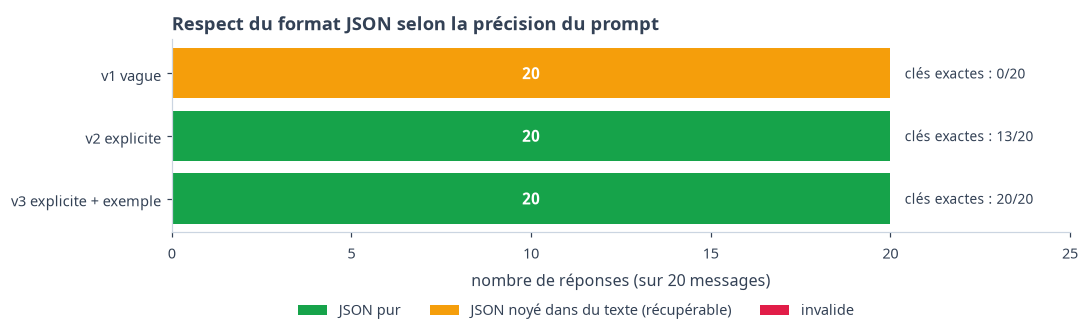

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(tab))
for col, c, lab in [("ok", GREEN, "JSON pur"), ("extrait", AMBER, "JSON noyé dans du texte (récupérable)"),
                    ("invalide", ROSE, "invalide")]:
    ax.barh(range(len(tab)), tab[col], left=left, color=c, label=lab)
    for i, (l, w) in enumerate(zip(left, tab[col])):
        if w:
            ax.text(l + w / 2, i, str(w), ha="center", va="center", color="white", fontweight="bold")
    left += tab[col].values
for i, v in enumerate(tab["clés exactes"]):
    ax.text(20.4, i, f"clés exactes : {v}/20", va="center", fontsize=9)
ax.set_yticks(range(len(tab)), tab.index)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xlabel("nombre de réponses (sur 20 messages)")
ax.set_title("Respect du format JSON selon la précision du prompt")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=3)
ax.grid(False)
finish(fig)
plt.show()

**Lecture.** Spécifier les clés et les valeurs permises, puis montrer un exemple, rapproche la
sortie du schéma attendu. Mais même un bon prompt ne **garantit** rien : pour une
application en production, on combine le prompt avec un **analyseur tolérant** (ici
`parse_json_output`, qui récupère un JSON entouré de texte), une validation de schéma, et
éventuellement des nouvelles tentatives ou un décodage contraint (outils cités par le livre :
Outlines, Instructor, Guidance ; voir l'exercice 5.7 et le chapitre 2).

> **À retenir.** Format compact, marqueur de fin, schéma explicite et exemple : quatre leviers
> simples sur le format de sortie. Aucun ne dispense de valider la sortie côté code.